# kukei probe_wave 波形・FFT スペクトル解析

`kukei_probe_sweep.py` が出力した NPZ ファイルから `probe_wave`（探触子受信波形）を読み込み，
波形の時間波形プロットと FFT スペクトルを表示する．

- **`probe_wave`** : 各時刻ステップにおける T1 の探触子開口平均値（x=1 行，探触子幅内の mean）
- `dt`, `n_steps` など物理パラメータは NPZ ファイルに収録済み

In [1]:
import sys
from pathlib import Path

# project4/Sourse を sys.path に追加して自所ライブラリをインポート
_sourse_dir = Path(r"C:\Users\cs16\lab\vscode\project1\sourse_new_2.py")
if str(_sourse_dir) not in sys.path:
    sys.path.insert(0, str(_sourse_dir))

import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401

import sourse_new_2 as source


# NPZ 読み込み・凡例ラベル（NPZ 固有のため notebook 内で定義）
def load_npz(path: Path) -> dict:
    raw = np.load(path, allow_pickle=True)
    return {k: raw[k] for k in raw.files}

def case_label(d: dict) -> str:
    return (
        f"pitch={float(d['f_pitch'])*1e3:.2f}mm "
        f"depth={float(d['f_depth'])*1e3:.2f}mm "
        f"align={str(d['alignment'])} "
        f"probe={str(d['probe_mode'])}"
    )

## 設定

**ここだけ編集する．**

In [2]:
# ===== ここを編集 =====

NPZ_DIR = Path(r"C:\Users\cs16\lab\vscode\project1\input")

# 解析する NPZ ファイルを列挙（空リストにするとフォルダ内の全 NPZ を使用）
NPZ_FILES: list[Path] = [
    NPZ_DIR / "C:\\Users\\cs16\\lab\\vscode\\project1\\input\\kukei_ani_pitch125_depth10_width25_psize700_data.npz",
]

# 平滑面（溝なし）の参照 NPZ。
# kukei_probe_sweep.py --smooth で生成する。
# None にするとスペクトル比率セルはスキップされる。
# SMOOTH_NPZ_FILE: Path | None = NPZ_DIR / "kukei_probe_sweep_smooth_probefixed_psize700.npz"
SMOOTH_NPZ_FILE = None

# ゲート設定
# ---------------------------------------------------------------
# GATE_START は入射波を飛ばしてテール波（反射波）を切り出すための開始ステップ。
# project2/Sourse の sim_gate_start に相当する。
#
# 入射ウェーブレット終端 ≈ 2.5 / 4.7MHz / dt ≈  750 step (≈ 0.53 µs)
# 反射波到着            ≈ 2 × (x_length/cl/dt) ≈ 9800 step (≈ 6.98 µs)
#
# → GATE_START は「入射波終端より後かつ反射波到着より前」に設定する。
#   デフォルト 5000 step (≈ 3.6 µs) は入射波後・反射波前の安全圏。
#   全体波形プロットでオレンジ帯が入射波に重ならないことを確認してから調整する。
# ---------------------------------------------------------------
GATE_START: int = 5000
GATE_LEFT:  int = 2 ** 10          # ピーク前に残すステップ数
GATE_RIGHT: int = (2 ** 10) * 3    # ピーク後に残すステップ数

# FFT パラメータ
FFT_N: int          = 2 ** 18      # ゼロパディング後の点数
FREQ_MIN_MHZ: float = 2.0          # スペクトル比率プロットの下限周波数 [MHz]（V_plot_data_1.py 準拠）
FREQ_MAX_MHZ: float = 8.0          # スペクトル比率プロットの上限周波数 [MHz]（V_plot_data_1.py 準拠）

# =====================

# NPZ_FILES が空ならフォルダ内の全 NPZ を収集（smooth ファイルは除外）
if not NPZ_FILES:
    NPZ_FILES = sorted(NPZ_DIR.glob("kukei_probe_sweep_*.npz"))
    NPZ_FILES = [p for p in NPZ_FILES if "smooth" not in p.name]

if NPZ_FILES:
    print(f"対象ファイル数: {len(NPZ_FILES)}")
    for p in NPZ_FILES:
        exists = "✓" if p.exists() else "✗ 未生成"
        print(f"  [{exists}] {p.name}")
else:
    print("[警告] NPZ ファイルが見つかりません。")
    print(f"  NPZ_DIR = {NPZ_DIR}")
    print("  まず kukei_probe_sweep.py を実行して NPZ を生成してください。")

if SMOOTH_NPZ_FILE is not None:
    exists = SMOOTH_NPZ_FILE.exists()
    status = "✓ 存在" if exists else "✗ 未生成（--smooth で実行してください）"
    print(f"平滑面参照: {SMOOTH_NPZ_FILE.name}  [{status}]")
else:
    print("[情報] SMOOTH_NPZ_FILE が未設定です。スペクトル比率セルはスキップされます。")

対象ファイル数: 1
  [✓] kukei_ani_pitch125_depth10_width25_psize700_data.npz
[情報] SMOOTH_NPZ_FILE が未設定です。スペクトル比率セルはスキップされます。


## メタデータ確認

In [3]:
if not NPZ_FILES:
    print("NPZ ファイルがありません。設定セルを確認してください。")
else:
    d0 = load_npz(NPZ_FILES[0])
    dt0 = float(d0["dt"])
    n_steps0 = int(d0["n_steps"])
    t_total_us = n_steps0 * dt0 * 1e6

    wavelet_end = int(2.5 / 4.7e6 / dt0)
    roundtrip_step = int(2 * 0.02 / (dt0 * source.cl))  # 往復ステップ概算

    print(f"ファイル        : {NPZ_FILES[0].name}")
    print(f"dt              : {dt0:.4e} s  ({1.0/dt0/1e6:.3f} Msps)")
    print(f"n_steps         : {n_steps0}  (計算時間 {t_total_us:.2f} µs)")
    print(f"alignment       : {str(d0['alignment'])}")
    print(f"probe_mode      : {str(d0['probe_mode'])}")
    print(f"pitch           : {float(d0['f_pitch'])*1e3:.3f} mm")
    print(f"groove width    : {float(d0['f_width'])*1e3:.3f} mm")
    print(f"depth           : {float(d0['f_depth'])*1e3:.3f} mm")
    print(f"probe aperture  : z=[{int(d0['probe_z_l'])}, {int(d0['probe_z_r'])})  "
          f"({(int(d0['probe_z_r'])-int(d0['probe_z_l'])) * float(d0['mesh_length'])*1e3:.2f} mm)")
    print(f"cl (source)     : {source.cl:.1f} m/s")
    print()
    print(f"[ゲート設定の目安]")
    print(f"  入射ウェーブレット終端 : step {wavelet_end}  ({wavelet_end * dt0 * 1e6:.2f} µs)")
    print(f"  反射波到着 (往復概算)  : step {roundtrip_step}  ({roundtrip_step * dt0 * 1e6:.2f} µs)")
    print(f"  → GATE_START は {wavelet_end}〜{roundtrip_step} の間に設定 (現在: {GATE_START})")
    if n_steps0 <= roundtrip_step:
        print(f"  [警告] n_steps={n_steps0} が反射波到着 {roundtrip_step} 以下です。")
        print(f"         TRAVEL_MULTIPLIER を 3.0 以上にして再実行してください。")

KeyError: 'dt'

## 全体波形プロット

ファイルごとに 1 行ずつ表示する．
赤色の縦の点線を基準に,左右に波形を切り出す.  レンジ帯がゲート範囲．　切り出した波形についてこれからあつかう

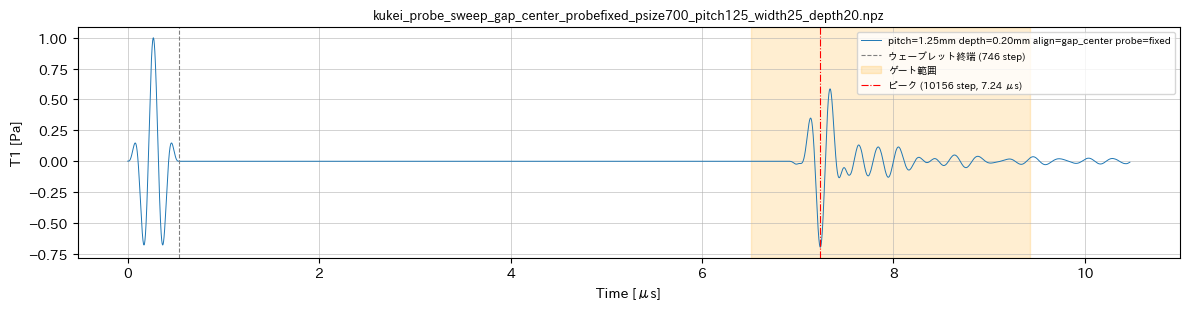


ファイル名                                                    pitch[mm]  depth[mm]     peak[Pa]   peak_t[μs]       energy  gate_start[step]
--------------------------------------------------------------------------------------------------------------------------------------
kukei_probe_sweep_gap_center_probefixed_psize700_pitch125_width25_depth20.npz      1.250      0.200   9.9923e-01        0.267   1.5706e-07              9132


In [ ]:
if not NPZ_FILES:
    print("NPZ ファイルがありません。")
else:
    n_files = len(NPZ_FILES)
    fig, axes = plt.subplots(n_files, 1, figsize=(12, 3.2 * n_files), squeeze=False)

    for ax, npz_path in zip(axes[:, 0], NPZ_FILES):
        d = load_npz(npz_path)
        probe_wave = d["probe_wave"]
        dt = float(d["dt"])
        n_steps = int(d["n_steps"])

        t_us = np.arange(n_steps) * dt * 1e6
        ax.plot(t_us, probe_wave, lw=0.7, color="tab:blue", label=case_label(d))

        wavelet_len_steps = int(2.5 / 4.7e6 / dt)
        ax.axvline(wavelet_len_steps * dt * 1e6, color="gray", lw=0.8, ls="--",
                   label=f"ウェーブレット終端 ({wavelet_len_steps} step)")

        _, peak_step, seg_start_step = source.kiritori(probe_wave, GATE_START, GATE_LEFT, GATE_RIGHT)
        seg_end_step = min(n_steps, seg_start_step + GATE_LEFT + GATE_RIGHT)
        ax.axvspan(seg_start_step * dt * 1e6, seg_end_step * dt * 1e6,
                   color="orange", alpha=0.18, label="ゲート範囲")
        ax.axvline(peak_step * dt * 1e6, color="red", lw=0.8, ls="-.",
                   label=f"ピーク ({peak_step} step, {peak_step * dt * 1e6:.2f} μs)")

        ax.set_xlabel("Time [μs]")
        ax.set_ylabel("T1 [Pa]")
        ax.set_title(npz_path.name, fontsize=9)
        ax.legend(fontsize=7, loc="upper right")
        ax.grid(True, lw=0.4)

    plt.tight_layout()
    plt.show()

    # ピーク・エネルギーのまとめ表
    print()
    header = (
        f"{'ファイル名':<55} "
        f"{'pitch[mm]':>10} {'depth[mm]':>10} "
        f"{'peak[Pa]':>12} {'peak_t[μs]':>12} "
        f"{'energy':>12} {'gate_start[step]':>17}"
    )
    print(header)
    print("-" * len(header))

    for npz_path in NPZ_FILES:
        d = load_npz(npz_path)
        probe_wave = d["probe_wave"]
        dt = float(d["dt"])

        _, peak_step, seg_start_step = source.kiritori(probe_wave, GATE_START, GATE_LEFT, GATE_RIGHT)
        peak_val  = float(np.max(np.abs(probe_wave)))
        peak_t_us = float(np.argmax(np.abs(probe_wave))) * dt * 1e6
        energy    = float(np.sum(probe_wave.astype(np.float64) ** 2) * dt)

        print(
            f"{npz_path.name:<55} "
            f"{float(d['f_pitch'])*1e3:>10.3f} {float(d['f_depth'])*1e3:>10.3f} "
            f"{peak_val:>12.4e} {peak_t_us:>12.3f} "
            f"{energy:>12.4e} {seg_start_step:>17}"
        )

## ゲート内波形プロット（複数ファイル重ね描き）

ゲート内の波形を相対時間軸（ゲート開始 = 0）で重ねて表示する．

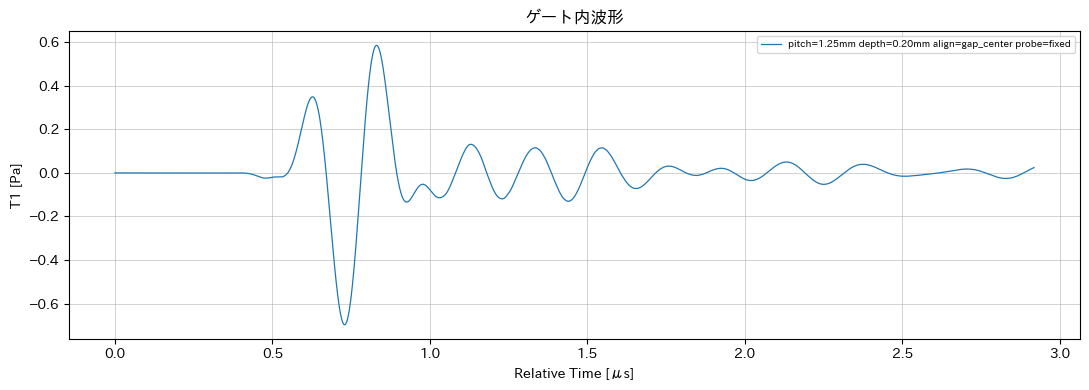

In [ ]:
if not NPZ_FILES:
    print("NPZ ファイルがありません。")
else:
    fig, ax = plt.subplots(figsize=(11, 4))

    for npz_path in NPZ_FILES:
        d = load_npz(npz_path)
        probe_wave = d["probe_wave"]
        dt = float(d["dt"])

        seg, _, _ = source.kiritori(probe_wave, GATE_START, GATE_LEFT, GATE_RIGHT)
        t_rel_us = np.arange(len(seg)) * dt * 1e6
        ax.plot(t_rel_us, seg, lw=0.9, label=case_label(d))

    ax.set_xlabel("Relative Time [μs]")
    ax.set_ylabel("T1 [Pa]")
    ax.set_title("ゲート内波形")
    ax.legend(fontsize=7)
    ax.grid(True, lw=0.4)
    plt.tight_layout()
    plt.show()

## FFT スペクトル（複数ファイル重ね描き）

ゲート内波形を `FFT_N` 点にゼロパディングして `rfft` を行う．

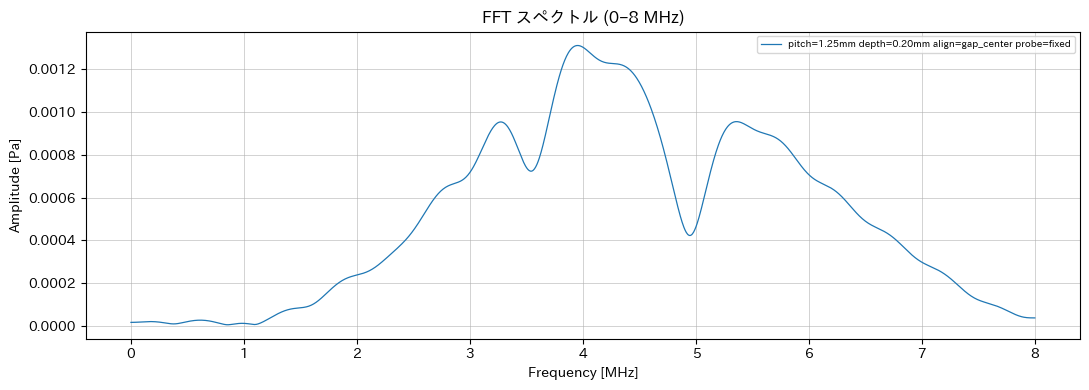

In [ ]:
if not NPZ_FILES:
    print("NPZ ファイルがありません。")
else:
    fig, ax = plt.subplots(figsize=(11, 4))

    for npz_path in NPZ_FILES:
        d = load_npz(npz_path)
        probe_wave = d["probe_wave"]
        dt = float(d["dt"])

        seg, _, _ = source.kiritori(probe_wave, GATE_START, GATE_LEFT, GATE_RIGHT)
        mag, freq = source.make_fft(seg, dt, FFT_N)

        band = freq <= FREQ_MAX_MHZ * 1e6
        ax.plot(freq[band] / 1e6, mag[band], lw=0.9, label=case_label(d))

    ax.set_xlabel("Frequency [MHz]")
    ax.set_ylabel("Amplitude [Pa]")
    ax.set_title(f"FFT スペクトル (0–{FREQ_MAX_MHZ:.0f} MHz)")
    ax.legend(fontsize=7)
    ax.grid(True, lw=0.4)
    plt.tight_layout()
    plt.show()

## 正規化スペクトル（最大値 = 1）

前節のスペクトルについて, 最大値を1.0 として正規化したもの．

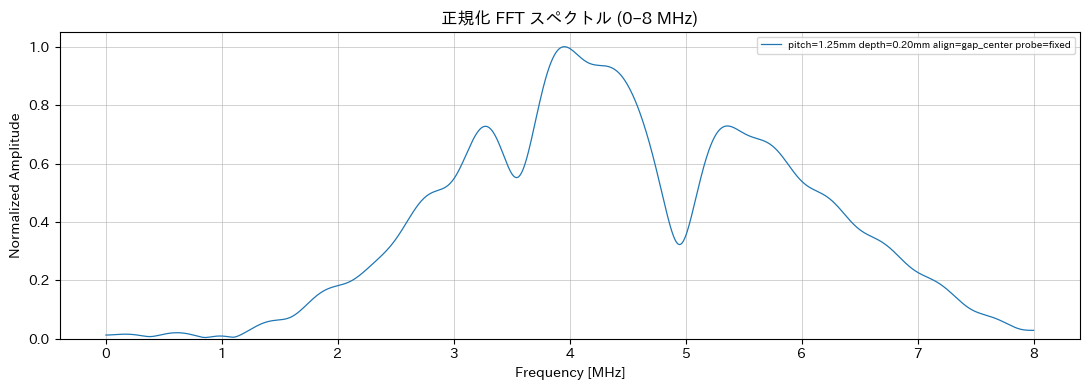

In [ ]:
if not NPZ_FILES:
    print("NPZ ファイルがありません。")
else:
    fig, ax = plt.subplots(figsize=(11, 4))

    for npz_path in NPZ_FILES:
        d = load_npz(npz_path)
        probe_wave = d["probe_wave"]
        dt = float(d["dt"])

        seg, _, _ = source.kiritori(probe_wave, GATE_START, GATE_LEFT, GATE_RIGHT)
        mag, freq = source.make_fft(seg, dt, FFT_N)

        band = freq <= FREQ_MAX_MHZ * 1e6
        mag_band = mag[band]
        if mag_band.max() > 0:
            mag_band = mag_band / mag_band.max()
        ax.plot(freq[band] / 1e6, mag_band, lw=0.9, label=case_label(d))

    ax.set_xlabel("Frequency [MHz]")
    ax.set_ylabel("Normalized Amplitude")
    ax.set_title(f"正規化 FFT スペクトル (0–{FREQ_MAX_MHZ:.0f} MHz)")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7)
    ax.grid(True, lw=0.4)
    plt.tight_layout()
    plt.show()

## スペクトル比率 FFT(傷あり) / FFT(平滑面)

ゲート内波形の FFT 振幅を平滑面（溝なし）で除算する。
- `kukei_probe_sweep.py --smooth` で平滑面 NPZ を先に生成し，設定セルの `SMOOTH_NPZ_FILE` に指定する。

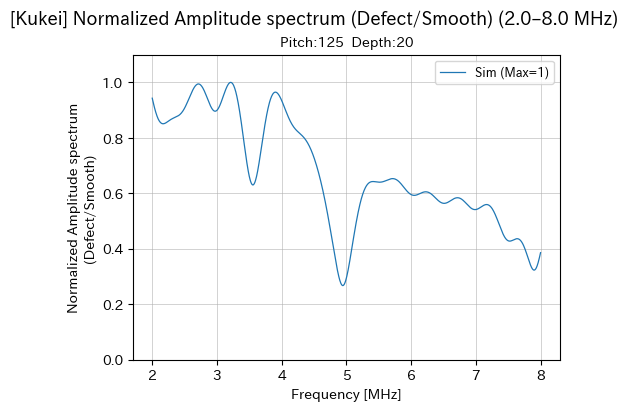

In [ ]:
if SMOOTH_NPZ_FILE is None:
    print("[スキップ] SMOOTH_NPZ_FILE が設定されていません。")
    print("  kukei_probe_sweep.py --smooth を実行してから SMOOTH_NPZ_FILE を指定してください。")
elif not SMOOTH_NPZ_FILE.exists():
    print(f"[スキップ] ファイルが見つかりません: {SMOOTH_NPZ_FILE}")
    print("  python kukei_probe_sweep.py --smooth  を先に実行してください。")
elif not NPZ_FILES:
    print("NPZ ファイルがありません。")
else:
    d_smooth = load_npz(SMOOTH_NPZ_FILE)
    dt_smooth = float(d_smooth["dt"])
    seg_smooth, _, _ = source.kiritori(d_smooth["probe_wave"], GATE_START, GATE_LEFT, GATE_RIGHT)
    mag_smooth, freq_smooth = source.make_fft(seg_smooth, dt_smooth, FFT_N)

    import math
    n_files = len(NPZ_FILES)
    cols = min(3, n_files)
    rows = math.ceil(n_files / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), constrained_layout=True)
    axes_flat = np.array(axes).flatten() if n_files > 1 else [axes]

    for i, npz_path in enumerate(NPZ_FILES):
        d = load_npz(npz_path)
        dt = float(d["dt"])
        seg, _, _ = source.kiritori(d["probe_wave"], GATE_START, GATE_LEFT, GATE_RIGHT)
        mag, freq = source.make_fft(seg, dt, FFT_N)

        band = (freq >= FREQ_MIN_MHZ * 1e6) & (freq <= FREQ_MAX_MHZ * 1e6)
        band_smooth = (freq_smooth >= FREQ_MIN_MHZ * 1e6) & (freq_smooth <= FREQ_MAX_MHZ * 1e6)
        ratio = mag[band] / (mag_smooth[band_smooth] + 1e-12)
        if ratio.max() > 0:
            ratio = ratio / ratio.max()

        ax = axes_flat[i]
        ax.plot(freq[band] / 1e6, ratio, color="tab:blue", lw=0.9, label="Sim (Max=1)")
        ax.set_title(
            f"Pitch:{int(float(d['f_pitch'])*1e5)}  Depth:{int(float(d['f_depth'])*1e5)}",
            fontsize=10
        )
        ax.set_ylim(0, 1.1)
        ax.grid(True, lw=0.4)
        if i % cols == 0:
            ax.set_ylabel("Normalized Amplitude spectrum\n(Defect/Smooth)")
        if i >= n_files - cols:
            ax.set_xlabel("Frequency [MHz]")
        if i == 0:
            ax.legend(loc="upper right", fontsize=9)

    for j in range(n_files, len(axes_flat)):
        axes_flat[j].axis("off")

    fig.suptitle(
        f"[Kukei] Normalized Amplitude spectrum (Defect/Smooth) "
        f"({FREQ_MIN_MHZ:.1f}–{FREQ_MAX_MHZ:.1f} MHz)",
        fontsize=13
    )
    plt.show()

## 正規化振幅スペクトル（傷あり / 平滑面）

前節の, スペクトル比率 FFT(傷あり) / FFT(平滑面) について, 最大値が1.0 となるように正規化したもの

- **ratio = 1.0** → 平滑面と同等（傷の影響なし）
- **ratio < 1.0** → その周波数帯が傷によって減衰している
- 上のセル（最大値 = 1 に正規化）と異なり，絶対的な減衰レベルが読み取れる。
- `sourse_new_2.py` の `select_pitch_and_image_exp` と同じ処理（ylim 0–1.5）。

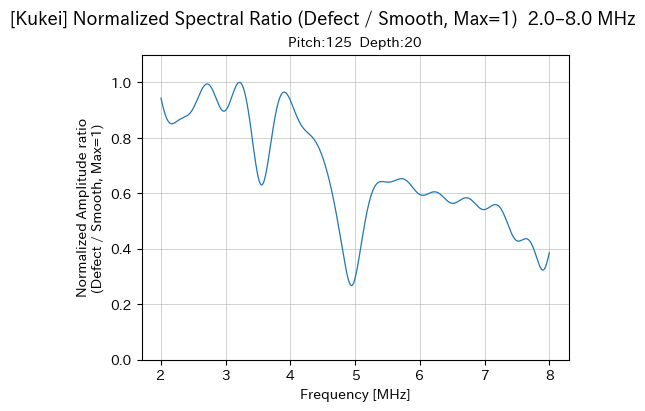

In [ ]:
if SMOOTH_NPZ_FILE is None:
    print("[スキップ] SMOOTH_NPZ_FILE が設定されていません。")
elif not SMOOTH_NPZ_FILE.exists():
    print(f"[スキップ] ファイルが見つかりません: {SMOOTH_NPZ_FILE}")
elif not NPZ_FILES:
    print("NPZ ファイルがありません。")
else:
    d_smooth = load_npz(SMOOTH_NPZ_FILE)
    dt_smooth = float(d_smooth["dt"])
    seg_smooth, _, _ = source.kiritori(d_smooth["probe_wave"], GATE_START, GATE_LEFT, GATE_RIGHT)
    mag_smooth, freq_smooth = source.make_fft(seg_smooth, dt_smooth, FFT_N)

    import math
    n_files = len(NPZ_FILES)
    cols = min(3, n_files)
    rows = math.ceil(n_files / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), constrained_layout=True)
    axes_flat = np.array(axes).flatten() if n_files > 1 else [axes]

    for i, npz_path in enumerate(NPZ_FILES):
        d = load_npz(npz_path)
        dt = float(d["dt"])
        seg, _, _ = source.kiritori(d["probe_wave"], GATE_START, GATE_LEFT, GATE_RIGHT)
        mag, freq = source.make_fft(seg, dt, FFT_N)

        band        = (freq        >= FREQ_MIN_MHZ * 1e6) & (freq        <= FREQ_MAX_MHZ * 1e6)
        band_smooth = (freq_smooth >= FREQ_MIN_MHZ * 1e6) & (freq_smooth <= FREQ_MAX_MHZ * 1e6)
        ratio = mag[band] / (mag_smooth[band_smooth] + 1e-12)
        if ratio.max() > 0:
            ratio = ratio / ratio.max()

        ax = axes_flat[i]
        ax.plot(freq[band] / 1e6, ratio, color="tab:blue", lw=0.9)
        ax.set_title(
            f"Pitch:{int(float(d['f_pitch'])*1e5)}  Depth:{int(float(d['f_depth'])*1e5)}",
            fontsize=10,
        )
        ax.set_ylim(0, 1.1)
        ax.grid(True, lw=0.4)
        if i % cols == 0:
            ax.set_ylabel("Normalized Amplitude ratio\n(Defect / Smooth, Max=1)")
        if i >= n_files - cols:
            ax.set_xlabel("Frequency [MHz]")

    for j in range(n_files, len(axes_flat)):
        axes_flat[j].axis("off")

    fig.suptitle(
        f"[Kukei] Normalized Spectral Ratio (Defect / Smooth, Max=1)  "
        f"{FREQ_MIN_MHZ:.1f}–{FREQ_MAX_MHZ:.1f} MHz",
        fontsize=13,
    )
    plt.show()